# Preprocessing: train/test split design

This notebook first decides **which basins have good enough streamflow records** to use, then fixes **how basins and years are split** between training and testing, before any scaling, PCA, clustering or model fitting happens. Everything downstream (clustering, LightGBM arms, the nearest-gauge baseline, the training-basin-count experiment) reads the tables written here, so all experiments share the same folds.

It follows the validation protocol from the feasibility review (issue 2):

| Requirement | How it is handled here |
| --- | --- |
| Hold out whole basins | Folds assign **basins**, never individual days |
| Spatially blocked folds | Basins are grouped into spatial blocks (complete-linkage clustering on great-circle distance); whole blocks go to one fold |
| Keep near-neighbours out of training | Optional **buffer**: training basins within `BUFFER_KM` of any test basin in that fold are dropped from training |
| Split in time | Train on early water years, test on later ones, with a one-year gap |
| Fit preprocessing on training basins only | Not done here: this notebook only defines the splits. Scalers, PCA and clustering are refit per fold downstream |

**Scope.** CAMELS-US (`camels`) and CAMELS-AUS (`camelsaus`) only. CAMELS-GB is left out entirely (the review treats it as a stretch goal).

It then prepares the model inputs that **don't depend on the fold**: a cleaned static-attribute table and a daily table with the log target and fixed weather windows. Anything that is fit to data (scalers, imputation, PCA, clustering) is left to downstream code, which fits it per fold.

**Outputs**

Quality filter, in `data/processed/` (committed):
- `quality_report.csv`: one row per extracted gauge (all regions, kept or not): valid years and missing fraction over the quality window, first and last valid dates, negative-flow count, `keep` flag and the reason a basin was dropped
- `basin_list.csv`: the kept gauge ids

Split design, in `data/processed/splits/` (committed):
- `basins.csv`: one row per basin: region, coordinates, spatial block, fold, and valid years of streamflow in the train and test periods
- `fold_roles.csv`: one row per (fold, basin): `test`, `train` or `buffer`, plus the distance from each training basin to the nearest test basin, so a different buffer can be applied without rerunning this notebook
- `config.json`: the periods and parameters used

Static features, in `data/processed/features/` (committed):
- `static_attributes.parquet`: one row per basin, attributes audited for leakage, climate indices recomputed from training-period forcing
- `feature_groups.json`: which columns are numeric features, categorical features and metadata, and which attributes were excluded and why

Daily model table, in `data/features/` (git-ignored, about 1 GB; rerun this notebook to rebuild it):
- `daily_<subset>.parquet`: one row per (basin, day) from the start of training to the end of testing, with the period label, raw and log streamflow, all forcings, and 7/30/90/365-day weather windows

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics.pairwise import haversine_distances

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

# Resolve paths from either the repository root or the notebooks folder.
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
# Add the project source directory so this notebook can reuse shard utilities.
sys.path.insert(0, str(REPO / "src"))
import combine_shards

PROCESSED = combine_shards.PROCESSED
COMBINED = combine_shards.COMBINED
SPLITS = PROCESSED / "splits"
# Keep compact committed tables separate from larger, regenerable daily output.
STATIC_OUT = PROCESSED / "features"          # small, committed
DAILY_OUT = REPO / "data" / "features"       # large, git-ignored

SUBSETS = ["camels", "camelsaus"]            # CAMELS-GB deliberately excluded
REGION = {"camels": "US", "camelsaus": "AUS"}
EARTH_RADIUS_KM = 6371.0
SEED = 780

## Parameters

All the choices this notebook makes are collected here. The sections below show the evidence behind each default.

**Periods.** Dates are water years starting 1 October (the US convention, applied to both regions so the cutoffs are identical everywhere).
- **Warm-up** (forcing only, no targets): 1985-10-01 to 1986-09-30. The longest weather window is 365 days, so the first training target needs a year of forcing before it.
- **Train**: 1986-10-01 to 2003-09-30 (17 water years).
- **Gap**: 2003-10-01 to 2004-09-30. Its flow is never used as a target, so autocorrelated flow can't carry over from training to testing. Its forcing is the warm-up for the test period's weather windows.
- **Test**: 2004-10-01 to 2014-09-30 (10 water years). Many US records end on 2014-09-30.

**Quality filter** (section 0).
- `QUALITY_WINDOW`: the span whose streamflow can become a target, from the start of training to the end of testing. Gaps outside it (before 1986-10 or after 2014-09) don't count against a basin; forcing from 1981 is still used for the weather windows.
- `MIN_VALID_YEARS`, `MAX_MISSING_FRAC`: a basin is kept if it has at least 15 years of valid streamflow and at most 15% of days missing in that window, and no negative flows. The committed time series hold every extracted gauge, so changing these only requires rerunning this notebook.

**Spatial design.**
- `BLOCK_KM`: the largest distance between any two basins in a block (complete linkage). 300 km is roughly where daily flow anomalies between basins fall to a median correlation of 0.5 (section 3).
- `N_FOLDS`: basin folds, stratified so each region is split evenly.
- `BUFFER_KM`: training basins this close to any test basin are dropped for that fold (section 5).
- `MIN_TRAIN_YEARS`, `MIN_TEST_YEARS`: valid streamflow needed for a basin to contribute targets in a period. Basins below the threshold are flagged, not dropped.

**Model inputs** (sections 7 and 8).
- `LOG_EPS`: the target is $\log(q + \varepsilon)$ with $q$ in mm/day. Zero flow is common (about 7% of US and 24% of AUS basin-days), so $\varepsilon$ is needed; 0.01 mm/day sits below almost all non-zero flows. Raw flow is kept too, so metrics can be computed in both spaces.
- `WINDOWS`, `WINDOW_VARS`: the fixed weather windows from the review (7/30/90/365 days), as trailing means ending on the prediction day, for precipitation, potential evaporation and mean temperature. Add variables to `WINDOW_VARS` if needed.

In [2]:
# Use the same water-year cutoffs for both regions.
PERIODS = {
    "warmup": ("1985-10-01", "1986-09-30"),
    "train":  ("1986-10-01", "2003-09-30"),
    "gap":    ("2003-10-01", "2004-09-30"),
    "test":   ("2004-10-01", "2014-09-30"),
}
# Streamflow quality filter, applied over the span that supplies targets (train start to test end).
QUALITY_WINDOW = (PERIODS["train"][0], PERIODS["test"][1])
MIN_VALID_YEARS = 15
MAX_MISSING_FRAC = 0.15

BLOCK_KM = 300
N_FOLDS = 5
BUFFER_KM = 100
# Minimum valid-flow coverage required for a basin to enter each evaluation period.
MIN_TRAIN_YEARS = 10
MIN_TEST_YEARS = 5

LOG_EPS = 0.01  # mm/day
# Trailing weather windows used later as daily model features.
WINDOWS = [7, 30, 90, 365]
WINDOW_VARS = {
    "total_precipitation_sum": "p",
    "potential_evaporation_sum_ERA5_LAND": "pet",
    "temperature_2m_mean": "t",
}

PERIODS_TS = {k: (pd.Timestamp(a), pd.Timestamp(b)) for k, (a, b) in PERIODS.items()}

## 0. Quality filter

`src/build_subset.py` stores **every** gauge it extracts from Caravan, unfiltered. This section decides which ones are usable, for all regions (GB included, so the filter is ready if GB comes back as a stretch goal):

- **valid years**: days with a streamflow value inside `QUALITY_WINDOW`, divided by 365.25
- **missing fraction**: share of days in `QUALITY_WINDOW` without a streamflow value
- **negative flows**: anywhere in the stored record (a data error, not a measurement)

It writes `quality_report.csv` (every gauge, with the `keep` flag and a drop reason) and `basin_list.csv` (kept ids) to `data/processed/`. Everything after this section uses kept basins only.

In [3]:
# Judge record quality only over the span that can supply targets.
q_start, q_end = map(pd.Timestamp, QUALITY_WINDOW)
n_window = (q_end - q_start).days + 1

# Rebuild the git-ignored combined files if they are missing or older than the committed shards.
all_subsets = combine_shards.available_subsets()
combine_shards.ensure_combined(all_subsets)

stats = []
for subset in all_subsets:
    q = pd.read_parquet(COMBINED / f"{subset}.parquet", columns=["gauge_id", "date", "streamflow"])
    q["date"] = pd.to_datetime(q["date"])
    has_flow = q.dropna(subset=["streamflow"])
    in_window = has_flow[has_flow["date"].between(q_start, q_end)]
    stats.append(pd.DataFrame({
        "subset": subset,
        "n_days": q.groupby("gauge_id").size(),
        "n_valid": in_window.groupby("gauge_id").size(),
        "first_valid": has_flow.groupby("gauge_id")["date"].min(),
        "last_valid": has_flow.groupby("gauge_id")["date"].max(),
        "n_negative": (q["streamflow"] < 0).groupby(q["gauge_id"]).sum(),
    }))
quality = pd.concat(stats).rename_axis("gauge_id").sort_index()
quality["n_valid"] = quality["n_valid"].fillna(0).astype(int)
quality["valid_years"] = quality["n_valid"] / 365.25
quality["missing_frac"] = 1 - quality["n_valid"] / n_window

# Record the first failed criterion so dropped basins can be explained.
quality["drop_reason"] = np.select(
    [quality["n_valid"] == 0,
     quality["n_negative"] > 0,
     quality["missing_frac"] > MAX_MISSING_FRAC,
     quality["valid_years"] < MIN_VALID_YEARS],
    ["no flow in window", "negative flow", "too much missing", "too few valid years"],
    default="",
)
quality["keep"] = quality["drop_reason"] == ""
quality = quality[["subset", "n_days", "n_valid", "valid_years", "missing_frac", "first_valid", "last_valid",
                   "n_negative", "keep", "drop_reason"]]

quality.to_csv(PROCESSED / "quality_report.csv")
quality.loc[quality["keep"], ["subset"]].to_csv(PROCESSED / "basin_list.csv")
kept_ids = set(quality.index[quality["keep"]])

summary = quality.groupby("subset").agg(extracted=("keep", "size"), kept=("keep", "sum"))
summary = summary.join(pd.crosstab(quality["subset"], quality["drop_reason"]).drop(columns="", errors="ignore"))
summary.loc["total"] = summary.sum()
summary

,extracted,kept,too much missing
subset,,,
camels,671,667,4
camelsaus,561,541,20
camelsgb,671,620,51
total,1903,1828,75


## 1. Basins in scope

Start from the basins kept by the quality filter (section 0) and drop CAMELS-GB.

In [4]:
# Start with basins from the two included datasets and retain split metadata.
attrs = pd.read_parquet(PROCESSED / "attributes.parquet")
# Coordinates and basin area support the spatial design and diagnostics below.
basins = (
    attrs.loc[attrs["subset"].isin(SUBSETS) & attrs.index.isin(kept_ids), ["subset", "gauge_name", "gauge_lat", "gauge_lon", "area"]]
    .rename(columns={"gauge_lat": "lat", "gauge_lon": "lon"})
    .rename_axis("gauge_id")
    .sort_index()
)
basins.insert(1, "region", basins["subset"].map(REGION))
print(basins["region"].value_counts().to_string())
basins.head()

region
US     667
AUS    541


,subset,region,gauge_name,lat,lon,area
gauge_id,,,,,,
camels_01013500,camels,US,"Fish River near Fort Kent, Maine",47.23739,-68.58264,2297.683155
camels_01022500,camels,US,"Narraguagus River at Cherryfield, Maine",44.60797,-67.93524,619.102595
camels_01030500,camels,US,"Mattawamkeag River near Mattawamkeag, Maine",45.50097,-68.30596,3666.943011
camels_01031500,camels,US,"Piscataquis River near Dover-Foxcroft, Maine",45.17501,-69.31470,764.824149
camels_01047000,camels,US,"Carrabassett River near North Anson, Maine",44.86920,-69.95510,902.895076


## 2. Temporal split

Load daily streamflow for both regions and count valid years in each period. A basin with too little valid flow in a period stays in the tables (its forcing and attributes still exist), but it is flagged so downstream code can skip it as a source of training targets or as a scored test basin.

In [5]:
# Combined files were refreshed in section 0 if they were missing or stale.

flow = pd.concat(
    [pd.read_parquet(COMBINED / f"{s}.parquet", columns=["gauge_id", "date", "streamflow"]) for s in SUBSETS],
    ignore_index=True,
)
# Normalize dates and discard records outside the selected basin set.
flow["date"] = pd.to_datetime(flow["date"])
flow = flow[flow["gauge_id"].isin(basins.index)]


def period_of(dates: pd.Series) -> pd.Series:
    out = pd.Series(pd.NA, index=dates.index, dtype="string")
    for name, (start, end) in PERIODS_TS.items():
        out[(dates >= start) & (dates <= end)] = name
    return out


# Label each observation by its predefined time period, then assess coverage.
flow["period"] = period_of(flow["date"])
# Count non-missing daily flow as an approximate number of usable years.
valid_years = (
    flow.dropna(subset=["streamflow"])
    .groupby(["gauge_id", "period"]).size()
    .unstack(fill_value=0)
    .reindex(index=basins.index, columns=list(PERIODS), fill_value=0)
    / 365.25
)
basins["train_valid_years"] = valid_years["train"].round(2)
basins["test_valid_years"] = valid_years["test"].round(2)
basins["usable_train"] = basins["train_valid_years"] >= MIN_TRAIN_YEARS
basins["usable_test"] = basins["test_valid_years"] >= MIN_TEST_YEARS

nominal = {k: round((b - a).days / 365.25 + 1 / 365.25, 1) for k, (a, b) in PERIODS_TS.items()}
print("nominal period lengths (years):", nominal)
basins.groupby("region")[["train_valid_years", "test_valid_years", "usable_train", "usable_test"]].agg(
    ["mean", "min"]
).round(2)

nominal period lengths (years): {'warmup': 1.0, 'train': 17.0, 'gap': 1.0, 'test': 10.0}


train_valid_years        test_valid_years       usable_train        \
                    mean    min             mean   min         mean   min   
region                                                                      
AUS                16.76  13.01             9.88  6.11          1.0  True   
US                 16.92  14.00             9.87  6.00          1.0  True   

       usable_test        
              mean   min  
region                    
AUS            1.0  True  
US             1.0  True

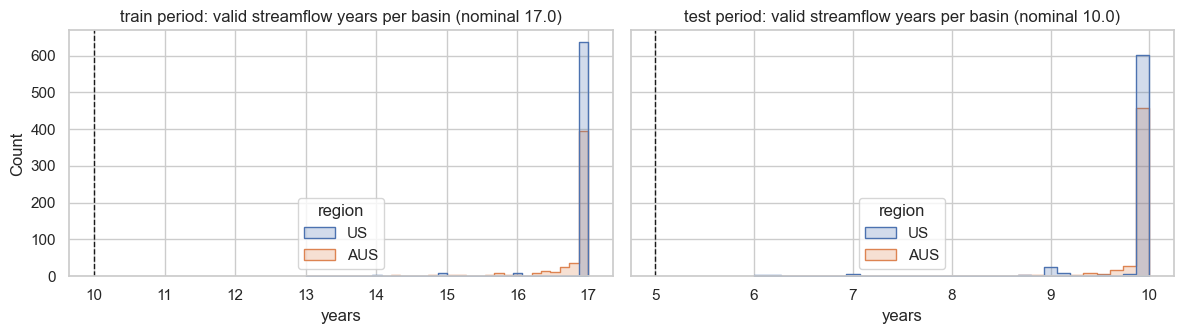

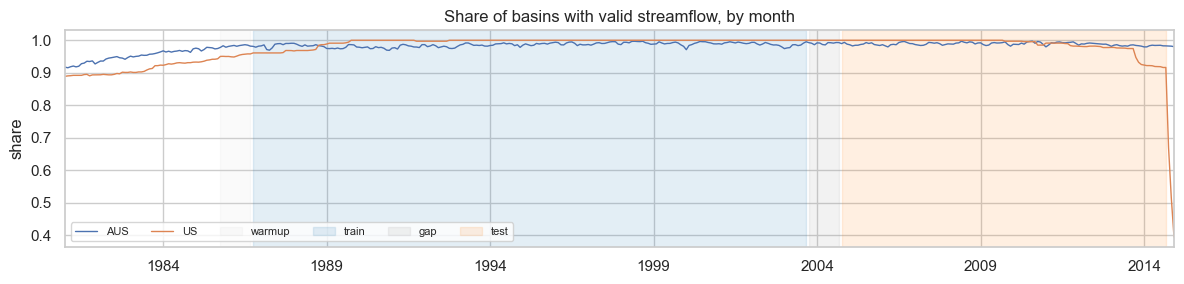

In [6]:
# Compare usable flow coverage across basins and over calendar time.
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
# Dashed vertical lines mark the minimum coverage used to retain a basin.
for ax, period, nmin in zip(axes, ["train", "test"], [MIN_TRAIN_YEARS, MIN_TEST_YEARS]):
    sns.histplot(data=basins, x=f"{period}_valid_years", hue="region", bins=30, ax=ax, element="step")
    ax.axvline(nmin, color="k", ls="--", lw=1)
    ax.set(title=f"{period} period: valid streamflow years per basin (nominal {nominal[period]})", xlabel="years")
plt.tight_layout()

# share of basin-days with valid flow over time, with the period boundaries marked
# Normalize by every basin in a region so missing-flow coverage remains visible.
n_basins = basins["region"].value_counts()
valid_per_day = (
    flow.assign(valid=flow["streamflow"].notna(), region=flow["gauge_id"].map(basins["region"]))
    .groupby(["date", "region"])["valid"].sum().unstack()
)
cover = (valid_per_day / n_basins).resample("MS").mean()  # denominator: all basins in the region
ax = cover.plot(figsize=(12, 3), lw=1)
colors = {"warmup": "0.85", "train": "tab:blue", "gap": "0.6", "test": "tab:orange"}
for name, (a, b) in PERIODS_TS.items():
    ax.axvspan(a, b, color=colors[name], alpha=0.12, label=name)
ax.set(title="Share of basins with valid streamflow, by month", ylabel="share", xlabel="")
ax.legend(ncol=6, fontsize=8, loc="lower left")
plt.tight_layout()

## 3. How far does neighbour information reach?

The worry in the review is that a test basin's near neighbours sit in the training set and hand the model (and the nearest-gauge baseline) information it would not have at a truly ungauged site. To size the spatial blocks, measure how similar two basins' flow is as a function of the distance between them.

For each pair of basins in the same region:
1. take daily log flow, $\log(q + 0.01)$, in the **training period only** (so test years never influence the split),
2. subtract each basin's day-of-year mean, so that two basins aren't "similar" just because both have a wet season,
3. correlate the anomalies (at least 3 years of overlap required).

Most of this similarity comes from shared weather, which the models will see anyway through each basin's own forcing. So this is a conservative (generous) measure of how far neighbour information reaches. It is used only to choose a sensible block size, not as an exact cut-off.

In [7]:
# Convert great-circle distances from radians to kilometers.
def distance_matrix_km(lat, lon) -> np.ndarray:
    # The haversine implementation expects latitude/longitude in radians.
    X = np.radians(np.column_stack([lat, lon]))
    return haversine_distances(X) * EARTH_RADIUS_KM


# Estimate within-region flow similarity using training years only.
train_start, train_end = PERIODS_TS["train"]
tr_flow = flow[(flow["date"] >= train_start) & (flow["date"] <= train_end)]

pairs = []
for subset in SUBSETS:
    ids = basins.index[basins["subset"] == subset]
    # Align one flow series per basin on shared dates before computing correlations.
    wide = tr_flow[tr_flow["gauge_id"].isin(ids)].pivot(index="date", columns="gauge_id", values="streamflow")[ids]
    logq = np.log(wide + 0.01)
    anom = logq - logq.groupby(logq.index.dayofyear).transform("mean")
    corr = anom.corr(min_periods=3 * 365).to_numpy()
    D = distance_matrix_km(basins.loc[ids, "lat"], basins.loc[ids, "lon"])
    iu = np.triu_indices_from(D, k=1)
    pairs.append(pd.DataFrame({"region": REGION[subset], "dist_km": D[iu], "r": corr[iu]}).dropna())
pairs = pd.concat(pairs, ignore_index=True)

bins = [0, 25, 50, 75, 100, 150, 200, 300, 400, 600, 800, 1200, 2000, 5000]
pairs["dist_bin"] = pd.cut(pairs["dist_km"], bins)
correlogram = pairs.groupby(["region", "dist_bin"], observed=True)["r"].describe()[["count", "25%", "50%", "75%"]]
correlogram.unstack(0)["50%"].round(2)

region,AUS,US
dist_bin,,
"(0, 25]",0.87,0.90
"(25, 50]",0.80,0.84
"(50, 75]",0.75,0.80
"(75, 100]",0.69,0.74
"(100, 150]",0.62,0.69
"(150, 200]",0.55,0.63
"(200, 300]",0.49,0.53
"(300, 400]",0.43,0.45
"(400, 600]",0.35,0.35


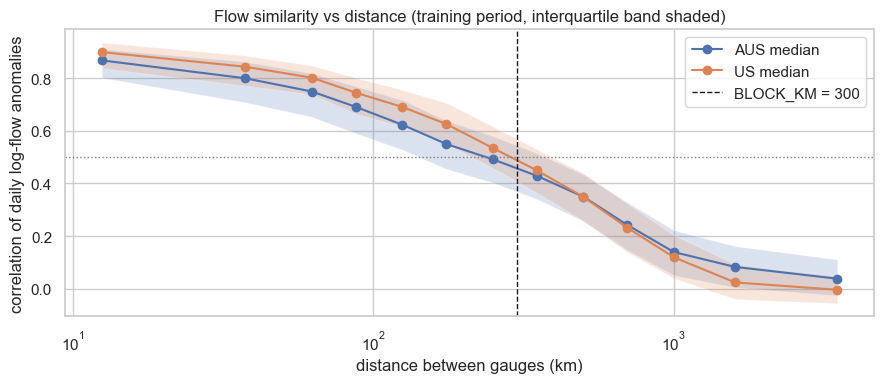

In [8]:
# Summarize the distribution of correlations at each gauge-distance range.
fig, ax = plt.subplots(figsize=(9, 4))
for region, g in correlogram.reset_index().groupby("region"):
    mid = g["dist_bin"].apply(lambda iv: (iv.left + iv.right) / 2)
    ax.plot(mid, g["50%"], marker="o", label=f"{region} median")
    # Shade the middle half of observed pairwise correlations in each distance bin.
    ax.fill_between(mid, g["25%"], g["75%"], alpha=0.2)
ax.axvline(BLOCK_KM, color="k", ls="--", lw=1, label=f"BLOCK_KM = {BLOCK_KM}")
ax.axhline(0.5, color="0.5", ls=":", lw=1)
ax.set(xscale="log", xlabel="distance between gauges (km)", ylabel="correlation of daily log-flow anomalies",
       title="Flow similarity vs distance (training period, interquartile band shaded)")
ax.legend()
plt.tight_layout()

**Reading the plot.** Similarity decays smoothly, with no sharp range. Basins within ~25 km are almost interchangeable (r ≈ 0.9), the median correlation crosses 0.5 at roughly 250–400 km, and it reaches about zero only beyond ~1,500 km. Blocking at that scale would leave only a handful of blocks per region, so the default is a compromise: 300 km blocks, plus a buffer that removes the closest training basins (section 5). Try `BLOCK_KM = 500` as a sensitivity check.

## 4. Spatial blocks and folds

**Blocks.** Within each region, complete-linkage agglomerative clustering on great-circle distance, cut at `BLOCK_KM`. Complete linkage guarantees that no two basins in a block are more than `BLOCK_KM` apart, so the blocks stay compact (single linkage would chain along dense coastlines). Regions are blocked separately; they are an ocean apart anyway.

**Folds.** Blocks are assigned to folds region by region, largest first, each to the fold with the fewest basins of that region so far (ties broken at random with `SEED`). Each fold therefore tests roughly 1/`N_FOLDS` of the US basins *and* of the AUS basins.

In [9]:
# Group nearby basins into blocks before assigning whole blocks to folds.
def spatial_blocks(df: pd.DataFrame, block_km: float) -> pd.Series:
    D = distance_matrix_km(df["lat"], df["lon"])
    # Complete linkage limits the largest within-block pairwise separation.
    labels = AgglomerativeClustering(
        n_clusters=None, metric="precomputed", linkage="complete", distance_threshold=block_km
    ).fit_predict(D)
    return pd.Series(labels, index=df.index)


def assign_folds(df: pd.DataFrame, n_folds: int, seed: int) -> pd.Series:
    rng = np.random.default_rng(seed)
    fold = pd.Series(-1, index=df.index)
    # Balance basin counts independently within each dataset/region.
    for _, g in df.groupby("subset"):
        sizes = g["block"].value_counts()
        order = sizes.sample(frac=1, random_state=int(rng.integers(1 << 31))).sort_values(ascending=False, kind="stable")
        load = np.zeros(n_folds)
        for block, n in order.items():
            candidates = np.flatnonzero(load == load.min())
            k = int(rng.choice(candidates))
            fold[g.index[g["block"] == block]] = k
            load[k] += n
    return fold


basins["block"] = ""
for subset, g in basins.groupby("subset"):
    lab = spatial_blocks(g, BLOCK_KM)
    basins.loc[g.index, "block"] = [f"{REGION[subset]}-{i:03d}" for i in lab]
basins["fold"] = assign_folds(basins, N_FOLDS, SEED)

block_sizes = basins.groupby(["region", "block"]).size()
print(basins.groupby("region")["block"].nunique().rename("n_blocks").to_string())
print("\nbasins per block:\n", block_sizes.groupby("region").describe()[["min", "50%", "max"]].to_string())
print("\nbasins per fold:")
pd.crosstab(basins["region"], basins["fold"], margins=True)

region
AUS    43
US     91

basins per block:
         min  50%   max
region                
AUS     1.0  6.0  75.0
US      1.0  6.0  28.0

basins per fold:


fold,0,1,2,3,4,All
region,,,,,,
AUS,108,108,109,108,108,541
US,133,134,133,134,133,667
All,241,242,242,242,241,1208


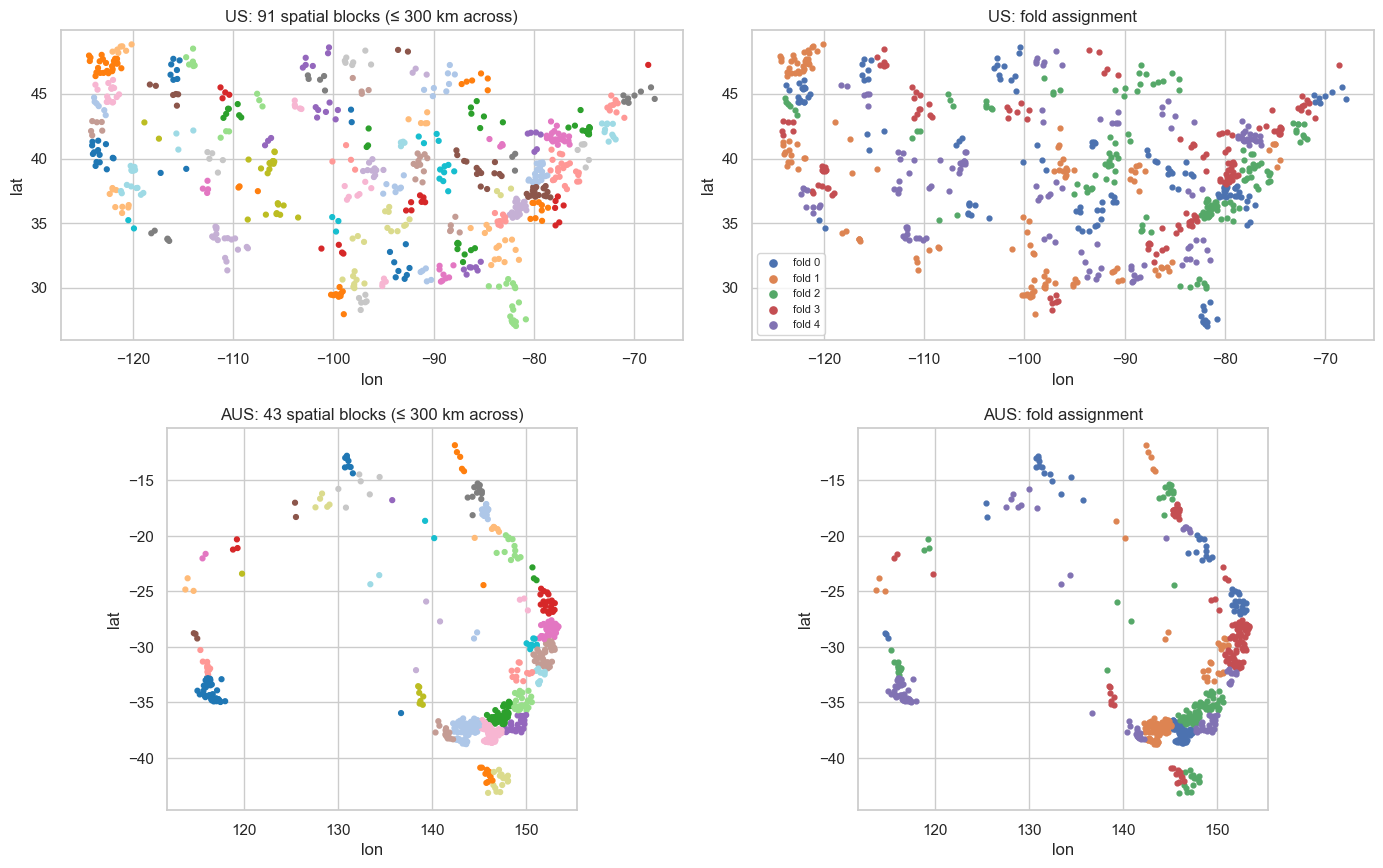

In [10]:
# Visualize the geographic blocks and the fold assignments they produce.
fig, axes = plt.subplots(2, 2, figsize=(14, 9), gridspec_kw={"height_ratios": [1, 1]})
for row, region in enumerate(["US", "AUS"]):
    g = basins[basins["region"] == region]
    # blocks: cycle a qualitative palette so neighbouring blocks are distinguishable
    codes = g["block"].astype("category").cat.codes
    axes[row, 0].scatter(g["lon"], g["lat"], c=codes % 20, cmap="tab20", s=12)
    axes[row, 0].set(title=f"{region}: {g['block'].nunique()} spatial blocks (≤ {BLOCK_KM} km across)")
    for k in range(N_FOLDS):
        # Each basin is colored by its assigned held-out fold.
        h = g[g["fold"] == k]
        axes[row, 1].scatter(h["lon"], h["lat"], s=12, label=f"fold {k}")
    axes[row, 1].set(title=f"{region}: fold assignment")
    for ax in axes[row]:
        ax.set(xlabel="lon", ylabel="lat")
        ax.set_aspect(1 / np.cos(np.radians(g["lat"].mean())))
axes[0, 1].legend(markerscale=1.5, fontsize=8)
plt.tight_layout()

## 5. Buffer: removing the closest training basins

Blocking keeps a test basin's own block out of training, but the neighbouring block may still be in training, just across the boundary. The buffer handles this: for each fold, any training basin within `BUFFER_KM` of a test basin is set to `buffer` (used neither for training nor testing in that fold).

First, see how many training basins each buffer size would cost.

region,AUS,US
buffer_km,,
0,100.0,100.0
25,99.8,100.0
50,97.2,99.6
100,88.1,93.3
150,74.9,80.4
200,64.1,66.8
300,48.0,45.2


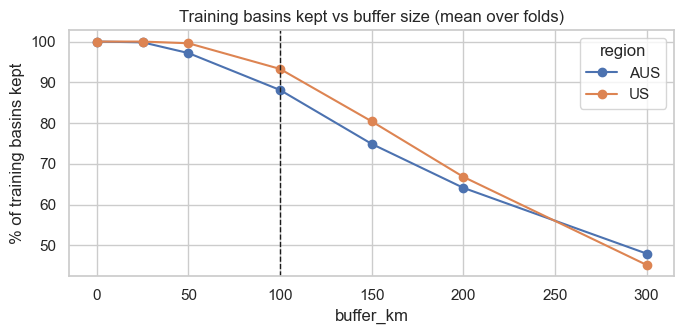

In [11]:
# Measure each basin's distance to the held-out fold in the same region.
D_all = distance_matrix_km(basins["lat"], basins["lon"])
region_arr = basins["region"].to_numpy()
same_region = region_arr[:, None] == region_arr[None, :]
fold_arr = basins["fold"].to_numpy()

# distance from every basin to the nearest test basin of the same region, per fold
rows = []
for k in range(N_FOLDS):
    is_test = fold_arr == k
    Dk = np.where(same_region[:, is_test], D_all[:, is_test], np.inf)
    rows.append(pd.DataFrame({
        "fold": k,
        "gauge_id": basins.index,
        "region": region_arr,
        "is_test": is_test,
        "dist_to_test_km": np.where(is_test, 0.0, Dk.min(axis=1)),
    }))
roles = pd.concat(rows, ignore_index=True)

buffers = [0, 25, 50, 100, 150, 200, 300]
retention = pd.DataFrame({
# Estimate how many non-test basins remain eligible as training data per buffer.
    b: roles[~roles["is_test"]].assign(kept=lambda d: d["dist_to_test_km"] >= b).groupby("region")["kept"].mean()
    for b in buffers
}).T.rename_axis("buffer_km")
ax = (100 * retention).plot(marker="o", figsize=(7, 3.5))
ax.axvline(BUFFER_KM, color="k", ls="--", lw=1)
ax.set(ylabel="% of training basins kept", title="Training basins kept vs buffer size (mean over folds)")
plt.tight_layout()
(100 * retention).round(1)

Now compare the three designs on the quantity that matters: **how far is each test basin from its nearest training basin?** Random basin folds (plain `KFold` on basins, which is what the proposal's `GroupKFold` by basin amounts to) are shown for reference.

0.1    0.5    0.9
region design                                      
AUS    blocks + 100 km buffer   111.0  168.0  273.0
       random basin folds         7.0   21.0   56.0
       spatial blocks (300 km)   48.0  113.0  235.0
US     blocks + 100 km buffer   112.0  157.0  244.0
       random basin folds        11.0   36.0   98.0
       spatial blocks (300 km)   73.0  134.0  220.0

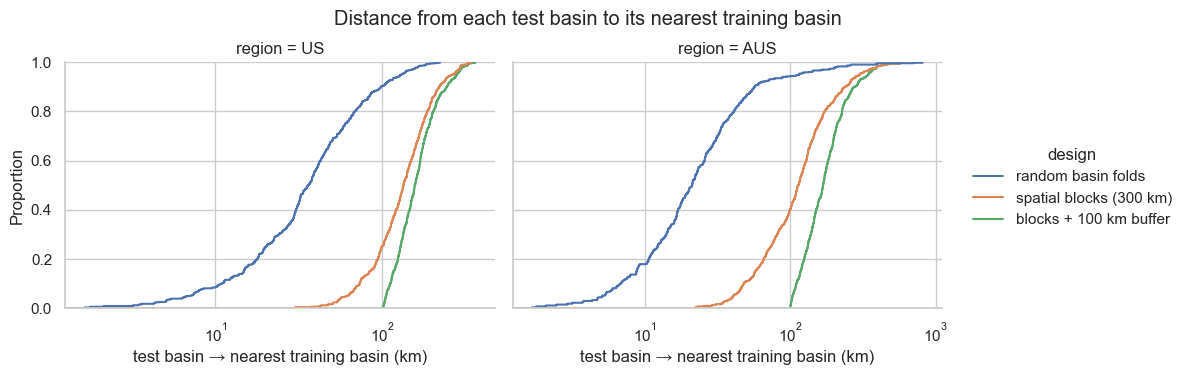

In [12]:
# Compare spatial separation for random, blocked, and buffered fold designs.
def nearest_train_km(fold_of: np.ndarray, excluded: np.ndarray | None = None) -> np.ndarray:
    # for each basin (as a test basin), distance to the nearest same-region training basin in its fold
    out = np.empty(len(fold_of))
    for i in range(len(fold_of)):
        train = (fold_of != fold_of[i]) & same_region[i]
        if excluded is not None:
            train &= ~excluded[fold_of[i]]
        out[i] = D_all[i, train].min()
    return out


rng = np.random.default_rng(SEED)
random_fold = rng.permutation(np.arange(len(basins)) % N_FOLDS)

# For each fold, flag non-test basins that would be removed by the saved buffer.
buffered = {
    k: ((roles["fold"] == k) & ~roles["is_test"] & (roles["dist_to_test_km"] < BUFFER_KM)).to_numpy()[
        (roles["fold"] == k).to_numpy()
    ]
    for k in range(N_FOLDS)
}
designs = {
    "random basin folds": nearest_train_km(random_fold),
    f"spatial blocks ({BLOCK_KM} km)": nearest_train_km(fold_arr),
    f"blocks + {BUFFER_KM} km buffer": nearest_train_km(fold_arr, buffered),
}
nn = pd.DataFrame(designs, index=basins.index).assign(region=region_arr)
nn_long = nn.melt(id_vars="region", var_name="design", value_name="km")

g = sns.displot(data=nn_long, x="km", hue="design", col="region", kind="ecdf", height=3.5, aspect=1.4,
                facet_kws={"sharex": False})
g.set(xscale="log", xlabel="test basin → nearest training basin (km)")
g.figure.suptitle("Distance from each test basin to its nearest training basin", y=1.04)
nn_long.groupby(["region", "design"])["km"].quantile([0.1, 0.5, 0.9]).unstack().round(0)

With random basin folds, the typical test basin has a training basin a few tens of km away, often a near-twin by the correlogram in section 3. Blocking pushes that distance up, and the buffer sets a hard floor at `BUFFER_KM` for every test basin. The nearest-gauge baseline must use the same donors, so it too will look worse than it would under random folds. That is the honest comparison.

## 6. Write the split tables

`fold_roles.csv` stores `dist_to_test_km` for every training basin, so a downstream script can apply a different buffer (`role = "buffer" if dist_to_test_km < my_buffer`) without rerunning this notebook. The `role` column uses `BUFFER_KM` from above.

In [13]:
# Save one role per basin and fold so downstream runs can reuse this design.
roles["role"] = np.where(roles["is_test"], "test", np.where(roles["dist_to_test_km"] < BUFFER_KM, "buffer", "train"))
# Store both the assigned IDs and every parameter needed to reproduce the split.
roles = roles.drop(columns="is_test")
roles["dist_to_test_km"] = roles["dist_to_test_km"].round(1)

SPLITS.mkdir(parents=True, exist_ok=True)
basin_cols = ["region", "subset", "gauge_name", "lat", "lon", "area", "block", "fold",
              "train_valid_years", "test_valid_years", "usable_train", "usable_test"]
basins[basin_cols].to_csv(SPLITS / "basins.csv")
roles.to_csv(SPLITS / "fold_roles.csv", index=False)

config = {
    "subsets": SUBSETS,
    "periods": PERIODS,
    "quality_window": QUALITY_WINDOW,
    "min_valid_years": MIN_VALID_YEARS,
    "max_missing_frac": MAX_MISSING_FRAC,
    "block_km": BLOCK_KM,
    "n_folds": N_FOLDS,
    "buffer_km": BUFFER_KM,
    "min_train_years": MIN_TRAIN_YEARS,
    "min_test_years": MIN_TEST_YEARS,
    "seed": SEED,
    "log_eps": LOG_EPS,
    "windows": WINDOWS,
    "window_vars": WINDOW_VARS,
}
(SPLITS / "config.json").write_text(json.dumps(config, indent=2))

for p in sorted(SPLITS.iterdir()):
    print(f"{p.relative_to(REPO)}  ({p.stat().st_size / 1024:.0f} KB)")
pd.crosstab([roles["fold"], roles["region"]], roles["role"])

data\processed\splits\basins.csv  (157 KB)
data\processed\splits\config.json  (1 KB)
data\processed\splits\fold_roles.csv  (203 KB)


role         buffer  test  train
fold region                     
0    AUS         54   108    379
     US          46   133    488
1    AUS         41   108    392
     US          20   134    513
2    AUS         61   109    371
     US          45   133    489
3    AUS         27   108    406
     US          50   134    483
4    AUS         74   108    359
     US          18   133    516

## 7. Static attributes: leakage audit

`attributes.parquet` has 216 columns. Before anything is clustered or fed to a model, sort them into metadata, features and exclusions:

| Treatment | Columns | Why |
| --- | --- | --- |
| **Exclude: flow-derived** | `dis_m3_pmn/pmx/pyr`, `run_mm_syr`, `ria_ha_usu`, `riv_tc_usu`, `dor_pc_pva` | Modelled discharge and runoff from HydroATLAS (WaterGAP), and river area, river volume and degree of regulation, which HydroATLAS derives from that modelled discharge. The proposal excludes attributes derived from observed *or modelled* flow. |
| **Exclude: computed over test years** | Caravan climate indices (`p_mean`, `aridity_*`, `frac_snow`, `seasonality_*`, `moisture_index_*`, …) | Caravan computes them over the full forcing record, test years included. Replaced by versions recomputed from **training-period** forcing (suffix `_train`). The FAO Penman-Monteith, seasonality and moisture-index variants are not recomputed. Seasonality is still covered by HydroATLAS's monthly climate columns. |
| **Exclude: constant** | columns with a single value across all US and AUS basins | No information in any fold |
| **Metadata, not features** | `gauge_lat`, `gauge_lon`, `area`, `gauge_name`, `country`, `subset`, `area_fraction_used_for_aggregation` | Location would let a model memorise where a basin is, which brings back the neighbour information the spatial blocks remove. `area` is kept for the nearest-gauge baseline's area scaling and enters the features as `log_area`. |
| **Categorical features** | `*_cl_smj` | Class codes (biome, climate zone, lithology, …), stored as `category`, not numbers |
| **Numeric features** | everything else from HydroATLAS, plus `log_area` and the `_train` climate indices | |

HydroATLAS's own climate columns (`pre_mm_*`, `tmp_dc_*`, `pet_mm_*`, …) come from long-term climatologies built mostly before our test period, so they stay.

In [14]:
# Exclude leakage-prone or unsuitable attributes before defining static features.
FLOW_DERIVED = {
    "dis_m3_pmn": "modelled discharge (WaterGAP): lowest monthly mean at pour point",
    "dis_m3_pmx": "modelled discharge (WaterGAP): highest monthly mean at pour point",
    "dis_m3_pyr": "modelled discharge (WaterGAP): annual mean at pour point",
    "run_mm_syr": "modelled land-surface runoff",
    "ria_ha_usu": "river area, derived from modelled discharge",
    "riv_tc_usu": "river volume, derived from modelled discharge",
    "dor_pc_pva": "degree of regulation: reservoir volume relative to modelled discharge",
}
CARAVAN_CLIMATE = [
    "p_mean", "pet_mean_ERA5_LAND", "pet_mean_FAO_PM", "aridity_ERA5_LAND", "aridity_FAO_PM",
    "frac_snow", "high_prec_freq", "high_prec_dur", "low_prec_freq", "low_prec_dur",
    "moisture_index_ERA5_LAND", "moisture_index_FAO_PM", "seasonality_ERA5_LAND", "seasonality_FAO_PM",
]
METADATA_SRC = ["gauge_name", "country", "gauge_lat", "gauge_lon", "area", "area_fraction_used_for_aggregation", "subset"]

raw = attrs.loc[basins.index]
# Treat coded soil/land-cover columns separately from numeric predictors.
categorical = sorted(c for c in raw.columns if c.endswith("_cl_smj"))
candidates = [c for c in raw.columns if c not in set(FLOW_DERIVED) | set(CARAVAN_CLIMATE) | set(METADATA_SRC) | set(categorical)]
constant = sorted(c for c in candidates if raw[c].nunique() <= 1)
hydroatlas_numeric = sorted(c for c in candidates if c not in constant)

excluded = {
    # Keep exclusion reasons alongside the feature-group manifest for auditability.
    **FLOW_DERIVED,
    **{c: "computed over the full record incl. test years; see *_train replacements" for c in CARAVAN_CLIMATE},
    **{c: "constant across all US and AUS basins" for c in constant},
}
print(f"HydroATLAS numeric features: {len(hydroatlas_numeric)}")
print(f"categorical features: {len(categorical)}")
print(f"excluded: {len(FLOW_DERIVED)} flow-derived, {len(CARAVAN_CLIMATE)} full-record climate, {len(constant)} constant")
print("constant columns:", constant)

HydroATLAS numeric features: 170
categorical features: 10
excluded: 7 flow-derived, 14 full-record climate, 8 constant
constant columns: ['glc_pc_s05', 'glc_pc_s07', 'glc_pc_s10', 'glc_pc_s17', 'pnv_pc_s02', 'pnv_pc_s15', 'wet_pc_s05', 'wet_pc_s08']


### Climate indices from training-period forcing

The CAMELS-style indices, recomputed per basin from daily ERA5-Land forcing over the **training period only** (1986-10 to 2003-09):

| Column | Definition |
| --- | --- |
| `p_mean_train`, `pet_mean_train` | mean daily precipitation and potential evaporation (mm/day) |
| `aridity_train` | `pet_mean_train / p_mean_train` |
| `frac_snow_train` | share of precipitation falling on days with mean temperature below 0 °C |
| `high_prec_freq_train`, `high_prec_dur_train` | days per year with precipitation ≥ 5 × `p_mean_train`, and the mean length of such spells (days) |
| `low_prec_freq_train`, `low_prec_dur_train` | days per year with precipitation < 1 mm, and the mean length of such spells (days) |

In [15]:
def mean_run_length(flag: pd.Series, gauge: pd.Series) -> pd.Series:
    # mean length of consecutive True runs per gauge (rows sorted by gauge, date)
    new_run = flag.ne(flag.shift()) | gauge.ne(gauge.shift())
    run_id = new_run.cumsum()
    runs = pd.DataFrame({"gauge": gauge, "run": run_id, "flag": flag})[flag]
    return runs.groupby(["gauge", "run"]).size().groupby("gauge").mean()


# Recompute climate summaries from training-period daily forcing only.
def climate_indices(df: pd.DataFrame) -> pd.DataFrame:
    df = df.sort_values(["gauge_id", "date"])
    g = df.groupby("gauge_id")
    p_mean = g["p"].mean()
    n_years = g.size() / 365.25
    # Define wet extremes relative to each basin's mean and dry days by a fixed threshold.
    high = df["p"] >= 5 * df["gauge_id"].map(p_mean)
    low = df["p"] < 1
    out = pd.DataFrame({
        "p_mean_train": p_mean,
        "pet_mean_train": g["pet"].mean(),
        "frac_snow_train": df["p"].where(df["t"] < 0, 0).groupby(df["gauge_id"]).sum() / g["p"].sum(),
        "high_prec_freq_train": high.groupby(df["gauge_id"]).sum() / n_years,
        "high_prec_dur_train": mean_run_length(high, df["gauge_id"]),
        "low_prec_freq_train": low.groupby(df["gauge_id"]).sum() / n_years,
        "low_prec_dur_train": mean_run_length(low, df["gauge_id"]),
    })
    out.insert(2, "aridity_train", out["pet_mean_train"] / out["p_mean_train"])
    # Attach units and definitions to the derived columns for downstream interpretation.
    out.attrs["variable_descriptions"] = {
        "p_mean_train": "Mean daily precipitation during the training period (mm/day).",
        "pet_mean_train": "Mean daily potential evaporation during the training period (mm/day).",
        "aridity_train": "Ratio of mean potential evaporation to mean precipitation during the training period (dimensionless).",
        "frac_snow_train": "Share of precipitation falling on days with mean temperature below 0 °C during the training period (dimensionless).",
        "high_prec_freq_train": "Mean number of days per year with precipitation at least 5 times the basin's mean daily precipitation.",
        "high_prec_dur_train": "Mean length in days of consecutive runs with precipitation at least 5 times the basin's mean daily precipitation.",
        "low_prec_freq_train": "Mean number of days per year with precipitation below 1 mm.",
        "low_prec_dur_train": "Mean length in days of consecutive runs with precipitation below 1 mm.",
    }
    return out


clim_cols = {"total_precipitation_sum": "p", "potential_evaporation_sum_ERA5_LAND": "pet", "temperature_2m_mean": "t"}
clim = []
for subset in SUBSETS:
    ts = pd.read_parquet(COMBINED / f"{subset}.parquet", columns=["gauge_id", "date", *clim_cols])
    ts["date"] = pd.to_datetime(ts["date"])
    ts = ts[ts["gauge_id"].isin(basins.index) & ts["date"].between(*PERIODS_TS["train"])].rename(columns=clim_cols)
    clim.append(climate_indices(ts))
clim = pd.concat(clim).reindex(basins.index)
clim_train_cols = list(clim.columns)
assert clim.notna().all().all()
clim.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
p_mean_train,1208.0,2.680,0.982,0.590,1.983,2.625,3.228,7.310
pet_mean_train,1208.0,13.370,5.249,3.724,8.997,13.675,17.540,29.270
aridity_train,1208.0,5.492,2.744,0.874,3.635,5.134,6.638,21.983
frac_snow_train,1208.0,0.081,0.144,0.000,0.000,0.002,0.102,0.789
high_prec_freq_train,1208.0,19.128,3.013,7.883,17.295,19.413,21.413,25.354
high_prec_dur_train,1208.0,1.270,0.182,1.057,1.155,1.210,1.330,2.239
low_prec_freq_train,1208.0,241.860,31.676,149.418,221.524,239.421,264.496,336.896
low_prec_dur_train,1208.0,5.075,2.552,2.387,3.738,4.255,5.449,21.369


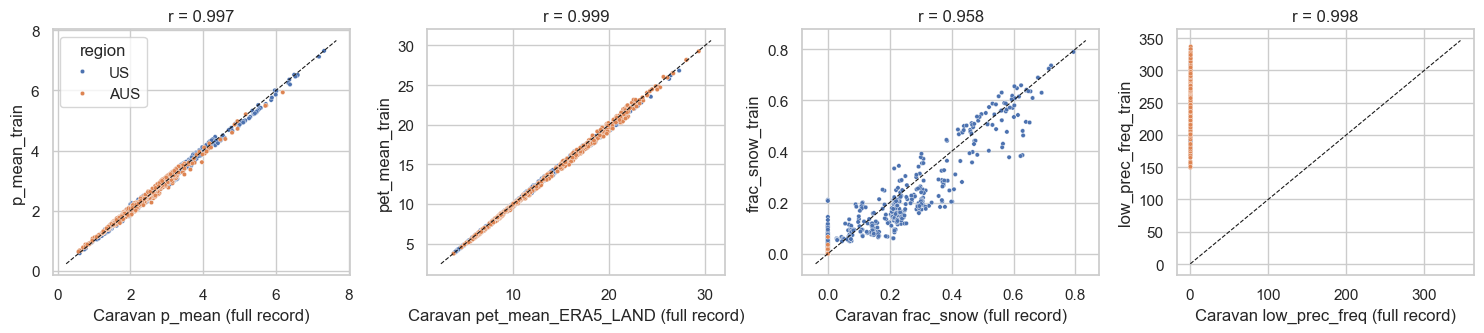

In [16]:
# Sanity check: training-period indices should track Caravan's full-record versions closely
# These comparisons are diagnostics; the model features below use the training-only values.
pairs_check = [("p_mean_train", "p_mean"), ("pet_mean_train", "pet_mean_ERA5_LAND"),
               ("frac_snow_train", "frac_snow"), ("low_prec_freq_train", "low_prec_freq")]
fig, axes = plt.subplots(1, len(pairs_check), figsize=(15, 3.5))
for ax, (ours, theirs) in zip(axes, pairs_check):
    sns.scatterplot(x=raw[theirs], y=clim[ours], hue=basins["region"], s=10, ax=ax, legend=ax is axes[0])
    lim = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lim, lim, "k--", lw=0.8)
    r = np.corrcoef(raw[theirs], clim[ours])[0, 1]
    ax.set(xlabel=f"Caravan {theirs} (full record)", ylabel=ours, title=f"r = {r:.3f}")
plt.tight_layout()

Close agreement is expected: these are the same forcings averaged over a shorter window (r ≥ 0.96 for every index). Where a point falls off the line, the test years differed from the training years, which is exactly the information that shouldn't reach the model. Caravan stores `high_prec_freq` and `low_prec_freq` as a fraction of days; ours are days per year, so only the correlation is comparable.

**ERA5-Land PET is inflated.** `pet_mean_train` has a median of about 14 mm/day, matching Caravan's `pet_mean_ERA5_LAND`, but Caravan's FAO Penman-Monteith estimate has a median of about 2.5 mm/day and HydroATLAS `pet_mm_syr` about 3.1 mm/day. ERA5-Land's potential evaporation is known to overestimate, which is why Caravan added the FAO variant. Absolute `aridity_train` values are therefore about 5× too high. Rankings between basins are preserved, so this matters little for scaled features or trees, but don't read `aridity_train` as a physical aridity index. If it matters, add Caravan's FAO Penman-Monteith PET column to `src/build_subset.py` and recompute from that.

In [17]:
# Assemble basin metadata, training-only climate indices, and eligible attributes.
static = pd.concat(
    [
        basins[["region", "subset", "gauge_name", "lat", "lon", "area"]],
        np.log10(basins[["area"]]).rename(columns={"area": "log_area"}),
        clim,
        raw[hydroatlas_numeric].astype("float64"),
        raw[categorical].astype("Int64").astype("category"),
    ],
    axis=1,
)
feature_groups = {
    # Separate model inputs from identifiers and excluded attributes.
    "metadata": ["region", "subset", "gauge_name", "lat", "lon", "area"],
    "numeric": ["log_area", *clim_train_cols, *hydroatlas_numeric],
    "categorical": categorical,
    "excluded": excluded,
}
assert static[feature_groups["numeric"]].notna().all().all()

STATIC_OUT.mkdir(parents=True, exist_ok=True)
static.to_parquet(STATIC_OUT / "static_attributes.parquet")
(STATIC_OUT / "feature_groups.json").write_text(json.dumps(feature_groups, indent=2))
print(static.shape, "->", (STATIC_OUT / "static_attributes.parquet").relative_to(REPO))
print({k: len(v) for k, v in feature_groups.items()})

(1208, 195) -> data\processed\features\static_attributes.parquet
{'metadata': 6, 'numeric': 179, 'categorical': 10, 'excluded': 29}


## 8. Daily model table

One row per (basin, day) from the start of training to the end of testing (gap year included, labelled `gap`), with:

- `period`: `train`, `gap` or `test`
- `streamflow` (mm/day) and `log_streamflow` = $\log(q + \varepsilon)$, with `LOG_EPS` stored in `config.json`
- all 16 ERA5-Land forcing columns for that day
- trailing weather windows, e.g. `p_mean_30d`: the mean over the 30 days ending on that day. They are computed from the full forcing record back to 1981, so even the first training day has a complete 365-day window. Windows use forcing only, never flow, so they carry nothing across the train/test boundary that the model wouldn't have at an ungauged site.
- `doy_sin`, `doy_cos`: day of year on the unit circle (southern-hemisphere seasons are captured by the forcing windows, not by these)

Fold membership is **not** stored here; join on `gauge_id` with `fold_roles.csv`. Days with missing streamflow are kept (their forcing is still valid for windows and for prediction); drop them when building targets.

In [18]:
# Define daily inputs and the rolling summaries to materialize for modeling.
FORCING = [
    "total_precipitation_sum", "temperature_2m_min", "temperature_2m_mean", "temperature_2m_max",
    "potential_evaporation_sum_ERA5_LAND", "snow_depth_water_equivalent_mean", "dewpoint_temperature_2m_mean",
    "surface_net_solar_radiation_mean", "surface_net_thermal_radiation_mean", "surface_pressure_mean",
    "u_component_of_wind_10m_mean", "v_component_of_wind_10m_mean",
    "volumetric_soil_water_layer_1_mean", "volumetric_soil_water_layer_2_mean",
    "volumetric_soil_water_layer_3_mean", "volumetric_soil_water_layer_4_mean",
]
window_cols = [f"{short}_mean_{w}d" for short in WINDOW_VARS.values() for w in WINDOWS]
DAILY_OUT.mkdir(parents=True, exist_ok=True)
start, end = PERIODS_TS["train"][0], PERIODS_TS["test"][1]

daily_summary = {}
for subset in SUBSETS:
    ts = pd.read_parquet(COMBINED / f"{subset}.parquet", columns=["gauge_id", "date", "streamflow", *FORCING])
    ts["date"] = pd.to_datetime(ts["date"])
    ts = ts[ts["gauge_id"].isin(basins.index)].sort_values(["gauge_id", "date"], ignore_index=True)

    # windows assume one row per calendar day per basin, with no gaps
    span = ts.groupby("gauge_id")["date"].agg(["min", "max", "size"])
    assert ((span["max"] - span["min"]).dt.days + 1 == span["size"]).all(), "non-contiguous daily records"
    assert not ts[FORCING].isna().any().any(), "missing forcing"

    by_gauge = ts.groupby("gauge_id", sort=False)
    # Rolling features use only the current and preceding days within each basin.
    for var, short in WINDOW_VARS.items():
        for w in WINDOWS:
            ts[f"{short}_mean_{w}d"] = (
                by_gauge[var].rolling(w, min_periods=w).mean().reset_index(level=0, drop=True).astype("float32")
            )

    ts = ts[ts["date"].between(start, end)].copy()
    ts["period"] = period_of(ts["date"]).astype(pd.CategoricalDtype(["train", "gap", "test"]))
    ts["log_streamflow"] = np.log(ts["streamflow"] + LOG_EPS).astype("float32")
    # Encode the annual cycle continuously rather than as a discontinuous day number.
    angle = 2 * np.pi * (ts["date"].dt.dayofyear - 1) / 365.25
    ts["doy_sin"] = np.sin(angle).astype("float32")
    ts["doy_cos"] = np.cos(angle).astype("float32")
    ts["gauge_id"] = ts["gauge_id"].astype("category")
    assert not ts[window_cols].isna().any().any(), "incomplete weather window"

    ts = ts[["gauge_id", "date", "period", "streamflow", "log_streamflow", *FORCING, *window_cols, "doy_sin", "doy_cos"]]
    path = DAILY_OUT / f"daily_{subset}.parquet"
    ts.to_parquet(path, index=False)
    daily_summary[subset] = {
        "basins": ts["gauge_id"].nunique(), "rows": len(ts), "columns": ts.shape[1],
        "missing_flow_pct": round(100 * ts["streamflow"].isna().mean(), 2),
        "file_MB": round(path.stat().st_size / 2**20),
    }
    del ts, by_gauge

pd.DataFrame(daily_summary).T

,basins,rows,columns,missing_flow_pct,file_MB
camels,667.0,6821409.0,35.0,0.77,388.0
camelsaus,541.0,5532807.0,35.0,1.30,293.0


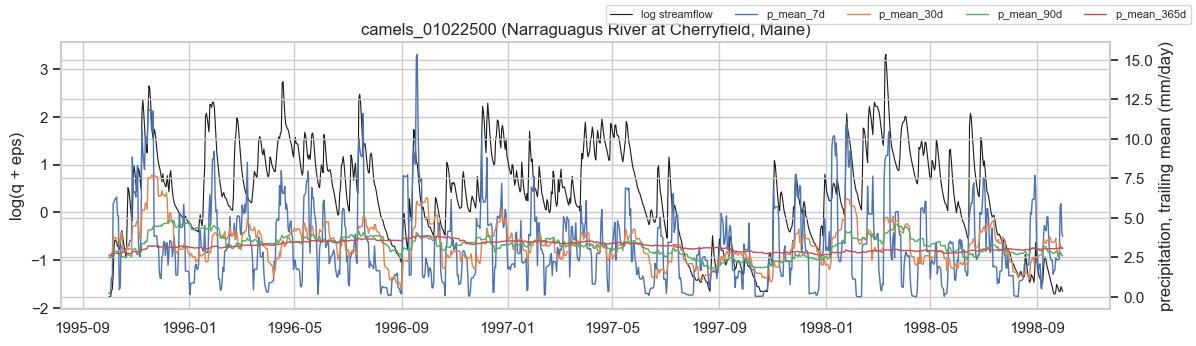

In [19]:
# Sanity check on one basin: log flow against the precipitation windows
# The second axis keeps precipitation in its own units beside log-transformed flow.
example = basins.index[1]
d = pd.read_parquet(DAILY_OUT / f"daily_{basins.loc[example, 'subset']}.parquet",
                    filters=[("gauge_id", "==", example)])
d = d[d["date"].between("1995-10-01", "1998-09-30")]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(d["date"], d["log_streamflow"], color="k", lw=0.8, label="log streamflow")
ax.set_ylabel("log(q + eps)")
ax2 = ax.twinx()
for w in WINDOWS:
    ax2.plot(d["date"], d[f"p_mean_{w}d"], lw=1, label=f"p_mean_{w}d")
ax2.set_ylabel("precipitation, trailing mean (mm/day)")
ax.set_title(f"{example} ({basins.loc[example, 'gauge_name']})")
fig.legend(loc="upper right", fontsize=8, ncol=5)
plt.tight_layout()

## 9. Using the outputs downstream

For fold `k`, a model is fit on the **train-period** days of `train` basins and scored on the **test-period** days of `test` basins. `buffer` basins are ignored in that fold. Everything fit to data (scalers, PCA, clustering, nearest-gauge donors) is fit on that fold's `train` basins only.

The training-basin-count experiment (25/50/100/all) subsamples from a fold's `train` basins; the `test` basins stay fixed so results are comparable across sizes.

The helpers below return one fold's basin ids and date ranges, the static features, and the daily rows for a set of basins and a period. They can be copied into a `src/` module once the modelling code needs them.

In [20]:
# Convenience loaders expose fold assignments and prepared features downstream.
def load_fold(k: int, buffer_km: float | None = None, splits_dir: Path = SPLITS) -> dict:
    # Basin ids and date ranges for fold k; pass buffer_km to override the saved buffer.
    cfg = json.loads((splits_dir / "config.json").read_text())
    info = pd.read_csv(splits_dir / "basins.csv", index_col="gauge_id")
    r = pd.read_csv(splits_dir / "fold_roles.csv").query("fold == @k").set_index("gauge_id")
    if buffer_km is not None:
        r["role"] = np.where(r["role"] == "test", "test", np.where(r["dist_to_test_km"] < buffer_km, "buffer", "train"))
    train = r.index[(r["role"] == "train") & info.loc[r.index, "usable_train"]]
    test = r.index[(r["role"] == "test") & info.loc[r.index, "usable_test"]]
    return {"train_basins": list(train), "test_basins": list(test),
            "train_period": cfg["periods"]["train"], "test_period": cfg["periods"]["test"],
            "warmup_period": cfg["periods"]["warmup"]}


def load_static(static_dir: Path = STATIC_OUT) -> tuple[pd.DataFrame, dict]:
    # Static table (index gauge_id) and the feature groups; use groups["numeric"] + groups["categorical"] as features.
    groups = json.loads((static_dir / "feature_groups.json").read_text())
    return pd.read_parquet(static_dir / "static_attributes.parquet"), groups


def load_daily(gauge_ids: list[str], period: str, columns: list[str] | None = None,
               daily_dir: Path = DAILY_OUT) -> pd.DataFrame:
    # Daily rows for these basins in one period ("train", "gap" or "test"), across regions.
    frames = []
    for subset in sorted({g.split("_")[0] for g in gauge_ids}):
        ids = [g for g in gauge_ids if g.startswith(subset + "_")]
        cols = None if columns is None else ["gauge_id", "date", "period", *columns]
        df = pd.read_parquet(daily_dir / f"daily_{subset}.parquet", columns=cols,
                             filters=[("gauge_id", "in", ids), ("period", "==", period)])
        df["gauge_id"] = df["gauge_id"].astype(str)
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


f0 = load_fold(0)
print({k: (f"{len(v)} basins" if k.endswith("basins") else v) for k, v in f0.items()})

static_df, groups = load_static()
print("static:", static_df.shape, {k: len(v) for k, v in groups.items()})

train_days = load_daily(f0["train_basins"][:5], "train", columns=["log_streamflow", "p_mean_30d"])
print("daily (5 training basins, train period):", train_days.shape)
train_days.head()

{'train_basins': '867 basins', 'test_basins': '241 basins', 'train_period': ['1986-10-01', '2003-09-30'], 'test_period': ['2004-10-01', '2014-09-30'], 'warmup_period': ['1985-10-01', '1986-09-30']}
static: (1208, 195) {'metadata': 6, 'numeric': 179, 'categorical': 10, 'excluded': 29}
daily (5 training basins, train period): (31045, 5)


,gauge_id,date,period,log_streamflow,p_mean_30d
0,camels_01013500,1986-10-01,train,0.667829,4.095000
1,camels_01013500,1986-10-02,train,0.693147,4.032333
2,camels_01013500,1986-10-03,train,0.717840,4.032333
3,camels_01013500,1986-10-04,train,0.732368,4.292000
4,camels_01013500,1986-10-05,train,0.717840,4.073000


## Open questions for the team

- **Block size.** 300 km is a judgement call (section 3). A sensitivity run at 500 km would show how much the headline numbers depend on it.
- **Buffer size.** 100 km keeps most training basins (section 5). The buffer could also be swept as its own small experiment: skill vs buffer distance shows directly how much the models lean on neighbours.
- **Nested basins.** Caravan gives gauge points, not catchment polygons, so upstream/downstream pairs can't be identified exactly here. Pairs of nested gauges are usually well within 100 km, so the buffer covers most of them.
- **Borderline exclusions.** `ria_ha_usu`, `riv_tc_usu` and `dor_pc_pva` are excluded because HydroATLAS derives them from modelled discharge. That is a cautious call; they could be restored if the team decides only *observed* flow counts as leakage.
- **High-cardinality categoricals.** `cls_cl_smj`, `tec_cl_smj` and `fec_cl_smj` have dozens of classes, many specific to one region. They may act as near-identifiers, so consider dropping them or grouping them before modelling.
- **Seasonality.** Caravan's seasonality and moisture indices were dropped, not recomputed. HydroATLAS's monthly climate columns carry similar information; add a recomputed seasonality index if clustering needs one compact feature.